## Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import seaborn as sns

## Load the dataset

In [5]:
df = pd.read_csv("Stravl_Travel_Preference_Data.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (80301, 38)


,id,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_k,...,Rec_0,Rec_1,Rec_2,Rec_3,Rec_4,Rec_5,Rec_6,Rec_7,Rec_8,Rec_9
0,22871c2cb8ee11ec9a19fefb5d5b7ead,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],['2'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
1,89b7022ab8f011ec9a19fefb5d5b7ead,"['0', '1']",['3'],['2'],"['0', '3', '4', '5', '6', '7']","['0', '1', '2', '4']",['1'],['1'],['1'],['1'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
2,c64f6c36b8f011ec9a19fefb5d5b7ead,['1'],['1'],['2'],"['0', '1', '3', '4', '7']","['0', '2', '4', '7']",['1'],['1'],['1'],['0'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
3,1eb6079ab8f111ec9a19fefb5d5b7ead,['1'],['1'],['2'],['7'],['4'],['1'],['2'],['1'],['1'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1
4,285e9852b8f111ec9a19fefb5d5b7ead,['1'],['0'],['1'],['2'],"['2', '3', '4']",['0'],['1'],['0'],['0'],...,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1


## Check the dataset structure

In [6]:
print("Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Columns:
['id', 'form_a', 'form_b', 'form_c', 'form_f', 'form_g', 'form_h', 'form_i', 'form_j', 'form_k', 'form_r', 'form_rr', 'yes_swipes', 'no_swipes', 'maybe_swipes', 'Model', 'Retrieval', 'DynaMatch', 'Rating_0', 'Rating_1', 'Rating_2', 'Rating_3', 'Rating_4', 'Rating_5', 'Rating_6', 'Rating_7', 'Rating_8', 'Rating_9', 'Rec_0', 'Rec_1', 'Rec_2', 'Rec_3', 'Rec_4', 'Rec_5', 'Rec_6', 'Rec_7', 'Rec_8', 'Rec_9']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 80301 entries, 0 to 80300
Data columns (total 38 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            80301 non-null  str    
 1   form_a        80300 non-null  str    
 2   form_b        80298 non-null  str    
 3   form_c        80298 non-null  str    
 4   form_f        79844 non-null  str    
 5   form_g        79007 non-null  str    
 6   form_h        80300 non-null  str    
 7   form_i        80299 non-null  str    
 8   form_j        80299 non-null  

## Check missing values

In [7]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values.sort_values(ascending=False))

form_rr     67344
form_r      62677
Rec_5       15433
Rec_9       15433
Rec_8       15433
Rec_7       15433
Rec_6       15433
Rating_6    15425
Rating_7    15425
Rating_5    15425
Rating_8    15425
Rating_9    15425
Rec_2        4689
Rec_4        4689
Rec_3        4689
Rec_1        4688
Rec_0        4688
Rating_1     4682
Rating_0     4682
Rating_2     4682
Rating_3     4682
Rating_4     4682
form_g       1294
form_f        457
form_b          3
form_c          3
form_i          2
form_k          2
form_j          2
form_a          1
form_h          1
dtype: int64


## Define the preference fields

In [8]:
preference_cols = [
    'form_a',
    'form_b',
    'form_c',
    'form_f',
    'form_g',
    'form_h',
    'form_i',
    'form_j',
    'form_r',
    'form_rr'
]

print("Preference columns:", preference_cols)

Preference columns: ['form_a', 'form_b', 'form_c', 'form_f', 'form_g', 'form_h', 'form_i', 'form_j', 'form_r', 'form_rr']


## Convert the swipe lists into Python lists

In [9]:
def parse_swipes(value):
    if pd.isna(value):
        return []

    return ast.literal_eval(value)


df['yes_list'] = df['yes_swipes'].apply(parse_swipes)
df['no_list'] = df['no_swipes'].apply(parse_swipes)
df['maybe_list'] = df['maybe_swipes'].apply(parse_swipes)

print(df[['yes_list', 'no_list', 'maybe_list']].head())

                                         yes_list  \
0  [837, 779, 1315, 773, 621, 799, 794, 172, 190]   
1                                      [246, 579]   
2                                [526, 661, 1054]   
3             [305, 216, 142, 435, 65, 1202, 853]   
4                [1197, 359, 1428, 725, 1115, 42]   

                                             no_list maybe_list  
0  [1256, 855, 1259, 551, 55, 257, 648, 234, 209,...         []  
1          [126, 945, 865, 330, 1237, 1264, 824, 87]         []  
2                [1129, 933, 1030, 1009, 1362, 1130]      [715]  
3                                   [24, 1396, 1375]         []  
4                              [1407, 305, 150, 442]         []  


## Create traveller–destination pairs

This cell performs three operations:
1. Combines all three response lists.
2. Removes repeated responses for the same traveller and destination.
3. Identifies contradictory responses, such as the same traveller marking the same destination both Yes and No.

In [10]:
pair_labels = {}
traveller_preferences = {}

for row in df.itertuples(index=False):

    traveller_id = row.id

    traveller_preferences[traveller_id] = {
        col: getattr(row, col)
        for col in preference_cols
    }

    response_lists = {
        'Yes': row.yes_list,
        'No': row.no_list,
        'Maybe': row.maybe_list
    }

    for label, destinations in response_lists.items():

        for destination in set(destinations):

            destination_id = int(destination)

            key = (traveller_id, destination_id)

            if key not in pair_labels:
                pair_labels[key] = set()

            pair_labels[key].add(label)


print("Total unique traveller-destination pairs:", len(pair_labels))

conflicting_pairs = sum(
    1 for labels in pair_labels.values()
    if len(labels) > 1
)

print("Conflicting pairs:", conflicting_pairs)

Total unique traveller-destination pairs: 815133
Conflicting pairs: 1331


## Create the final modelling dataset

In [11]:
records = []

for (traveller_id, destination_id), labels in pair_labels.items():

    if len(labels) == 1:

        record = {
            'traveller_id': traveller_id,
            'destination_id': destination_id,
            'target': next(iter(labels))
        }

        record.update(traveller_preferences[traveller_id])

        records.append(record)


model_df = pd.DataFrame(records)

print("Modelling Dataset Shape:", model_df.shape)

model_df.head()

Modelling Dataset Shape: (813802, 13)


,traveller_id,destination_id,target,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_r,form_rr
0,22871c2cb8ee11ec9a19fefb5d5b7ead,1315,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
1,22871c2cb8ee11ec9a19fefb5d5b7ead,773,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
2,22871c2cb8ee11ec9a19fefb5d5b7ead,837,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
3,22871c2cb8ee11ec9a19fefb5d5b7ead,779,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
4,22871c2cb8ee11ec9a19fefb5d5b7ead,172,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN


## Create the final modelling dataset

In [12]:
records = []

for (traveller_id, destination_id), labels in pair_labels.items():

    if len(labels) == 1:

        record = {
            'traveller_id': traveller_id,
            'destination_id': destination_id,
            'target': next(iter(labels))
        }

        record.update(traveller_preferences[traveller_id])

        records.append(record)


model_df = pd.DataFrame(records)

print("Modelling Dataset Shape:", model_df.shape)

model_df.head()

Modelling Dataset Shape: (813802, 13)


,traveller_id,destination_id,target,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_r,form_rr
0,22871c2cb8ee11ec9a19fefb5d5b7ead,1315,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
1,22871c2cb8ee11ec9a19fefb5d5b7ead,773,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
2,22871c2cb8ee11ec9a19fefb5d5b7ead,837,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
3,22871c2cb8ee11ec9a19fefb5d5b7ead,779,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
4,22871c2cb8ee11ec9a19fefb5d5b7ead,172,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN


## Create the final modelling dataset

In [13]:
records = []

for (traveller_id, destination_id), labels in pair_labels.items():

    if len(labels) == 1:

        record = {
            'traveller_id': traveller_id,
            'destination_id': destination_id,
            'target': next(iter(labels))
        }

        record.update(traveller_preferences[traveller_id])

        records.append(record)


model_df = pd.DataFrame(records)

print("Modelling Dataset Shape:", model_df.shape)

model_df.head()

Modelling Dataset Shape: (813802, 13)


,traveller_id,destination_id,target,form_a,form_b,form_c,form_f,form_g,form_h,form_i,form_j,form_r,form_rr
0,22871c2cb8ee11ec9a19fefb5d5b7ead,1315,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
1,22871c2cb8ee11ec9a19fefb5d5b7ead,773,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
2,22871c2cb8ee11ec9a19fefb5d5b7ead,837,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
3,22871c2cb8ee11ec9a19fefb5d5b7ead,779,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN
4,22871c2cb8ee11ec9a19fefb5d5b7ead,172,Yes,"['0', '1']",['1'],['2'],"['0', '1', '2', '7']","['0', '2', '4']",['1'],['1'],['1'],NaN,NaN


## Check the target distribution

In [14]:
print("Target Distribution:")
print(model_df['target'].value_counts())

print("\nTarget Distribution in Percentage:")
print(
    model_df['target']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Target Distribution:
target
No       498184
Yes      288756
Maybe     26862
Name: count, dtype: int64

Target Distribution in Percentage:
target
No       61.22
Yes      35.48
Maybe     3.30
Name: proportion, dtype: float64


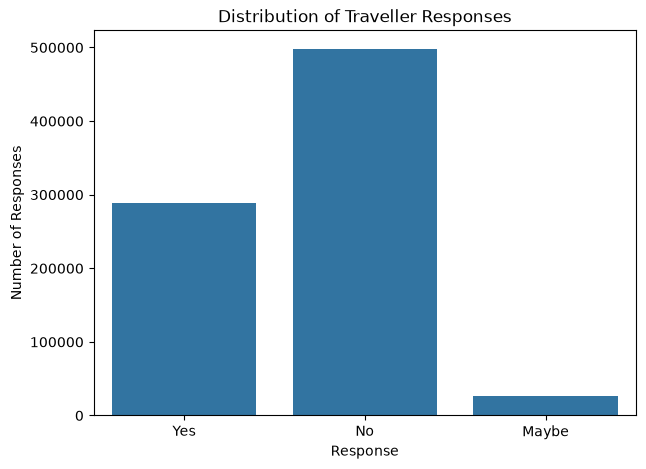

In [15]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=model_df,
    x='target',
    order=['Yes', 'No', 'Maybe']
)

plt.title("Distribution of Traveller Responses")
plt.xlabel("Response")
plt.ylabel("Number of Responses")
plt.show()